# 02 · Modeling with honest uncertainty

M1 gave point estimates only. This notebook:

1. Fixes a train / valid / test split by week (`configs/model.yaml`).
2. Adds past-only behavioural features and screens features with mutual information against a permutation null.
3. Compares logistic regression and LightGBM variants, each comparison with a **paired bootstrap CI of the difference**.
4. Shows how much the CI depends on what you resample: rows, days, or card holders.
5. Saves validation and test scores for calibration in M3.
6. Revisits the M1 split experiment with CIs, and separates "memorising people" from "new people are harder".

All logic lives in `src/fraud/`.

In [1]:
import gc
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_curve

from fraud.config import load_config
from fraud.data import ENTITY_COL, PROCESSED_DIR, TARGET, drop_seen_entities, load_dataset, random_split, split_by_week, time_split
from fraud.evaluate import bootstrap_ci, paired_bootstrap_diff, summarize
from fraud.features import add_past_features, add_row_features, feature_columns, screen_features
from fraud.train import fit_baseline, fit_lgbm, fit_logistic, log_run, predict

cfg = load_config("model")
N_BOOT, SEED = cfg["bootstrap"]["n_boot"], cfg["bootstrap"]["seed"]
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Data, features, split

In [2]:
df = load_dataset("train")
raw_features = feature_columns(df)
df = add_past_features(add_row_features(df))
all_features = feature_columns(df)
engineered = [f for f in all_features if f not in raw_features]
print(f"raw features: {len(raw_features)}, engineered: {len(engineered)}")

train, valid, test = split_by_week(df, cfg["split"]["valid_start_week"], cfg["split"]["test_start_week"])
pd.DataFrame({
    name: {"weeks": f"{part.week.min()}-{part.week.max()}", "rows": len(part), "fraud_rate": round(part[TARGET].mean(), 4)}
    for name, part in [("train", train), ("valid", valid), ("test", test)]
}).T

raw features: 431, engineered: 16


,weeks,rows,fraud_rate
train,0-15,386298,0.0342
valid,16-19,83079,0.0394
test,20-26,121163,0.0345


## 2. Feature screening: mutual information against a permutation null

The plug-in MI estimate is biased upwards by roughly (k − 1) / 2n nats for a feature with k bins (Miller–Madow). A feature with hundreds of categories therefore looks informative even if it is noise. Shuffling the label 20 times gives each feature its own null distribution; a feature is kept if its MI beats the 99th percentile of that null. Near-duplicate numeric features (|corr| > 0.98) are then dropped, keeping the one with the higher MI.

Screening uses a sample of the **train** weeks only.

In [3]:
sample = train.sample(cfg["screening"]["sample_size"], random_state=SEED)
screened, mi = screen_features(sample, all_features, cfg["screening"])
print(f"{len(all_features)} features -> {int(mi['keep'].sum())} beat the null -> {len(screened)} after removing near-duplicates")
print("dropped by the null:", sorted(mi.index[~mi["keep"]]))

447 features -> 420 beat the null -> 394 after removing near-duplicates
dropped by the null: ['C3', 'V104', 'V106', 'V107', 'V108', 'V109', 'V110', 'V111', 'V112', 'V113', 'V114', 'V115', 'V116', 'V117', 'V118', 'V119', 'V120', 'V121', 'V122', 'V123', 'V125', 'V135', 'V137', 'V281', 'V300', 'V301', 'weekday']


In [4]:
print("Highest-cardinality features: MI vs the bias the null corrects for")
display(mi.sort_values("n_bins", ascending=False).head(6).round(5))
print("Engineered features")
display(mi.loc[engineered].sort_values("mi", ascending=False).round(5))

Highest-cardinality features: MI vs the bias the null corrects for


,mi,null_q,miller_madow_bias,n_bins,keep
feature,,,,,
DeviceInfo,0.01425,0.00268,0.00471,944,True
id_33,0.00262,0.00051,0.00054,108,True
id_31,0.01013,0.00051,0.00050,100,True
id_30,0.00192,0.00045,0.00036,72,True
R_emaildomain,0.00994,0.00039,0.00030,60,True
P_emaildomain,0.00296,0.00041,0.00030,60,True


Engineered features


,mi,null_q,miller_madow_bias,n_bins,keep
feature,,,,,
amt_cents,0.00785,0.00008,0.00002,6,True
card1_past_mean_amt,0.00626,0.00013,0.00010,21,True
entity_key_secs_since_prev,0.00578,0.00015,0.00010,21,True
entity_key_n_7d,0.00505,0.00006,0.00002,6,True
entity_key_n_24h,0.00382,0.00005,0.00002,5,True
log_amt,0.00372,0.00017,0.00010,20,True
entity_key_n_1h,0.00237,0.00002,0.00001,3,True
entity_key_past_mean_amt,0.00227,0.00017,0.00010,21,True
card1_secs_since_prev,0.00177,0.00016,0.00010,21,True


In [5]:
# Significance is not usefulness: with 100k rows almost everything beats the null.
floors = [0, 1e-4, 5e-4, 1e-3, 5e-3]
pd.Series({f"MI > {f:g}": int((mi.loc[mi['keep'], 'mi'] > f).sum()) for f in floors}, name="features kept")

MI > 0         420
MI > 0.0001    412
MI > 0.0005    360
MI > 0.001     319
MI > 0.005     219
Name: features kept, dtype: int64

## 3. Models

- **Logistic regression** on the screened features. Dense one-hot + missing flags on all 386k rows do not fit in memory, so it trains on a uniform 150k-row sample.
- **LightGBM** with early stopping on validation PR-AUC. `num_leaves` is chosen on the validation weeks, using all features, then reused.

In [6]:
models, timings = {}, {}

t0 = time.time()
models["logistic"] = (fit_logistic(train, screened, C=cfg["logistic"]["C"], max_rows=cfg["logistic"]["max_rows"], seed=SEED), screened)
timings["logistic"] = time.time() - t0

grid = {}
for leaves in cfg["lgbm"]["num_leaves_grid"]:
    t0 = time.time()
    model = fit_lgbm(train, valid, all_features, cfg["lgbm"], num_leaves=leaves, seed=SEED)
    grid[leaves] = (model, model.best_score_["valid_0"]["average_precision"], model.best_iteration_, time.time() - t0)
best_leaves = max(grid, key=lambda k: grid[k][1])
pd.DataFrame({k: {"valid_pr_auc": v[1], "best_iteration": v[2], "seconds": round(v[3])} for k, v in grid.items()}).T

,valid_pr_auc,best_iteration,seconds
31,0.608182,553.0,63.0
63,0.622647,729.0,86.0
127,0.655815,2488.0,297.0


In [7]:
models["lgbm_all"] = (grid[best_leaves][0], all_features)
timings["lgbm_all"] = grid[best_leaves][3]
for name, features in [("lgbm_raw", raw_features), ("lgbm_screened", screened)]:
    t0 = time.time()
    models[name] = (fit_lgbm(train, valid, features, cfg["lgbm"], num_leaves=best_leaves, seed=SEED), features)
    timings[name] = time.time() - t0
print("best num_leaves:", best_leaves)

best num_leaves: 127


In [8]:
scores = {name: {"valid": predict(m, valid, f), "test": predict(m, test, f)} for name, (m, f) in models.items()}
y_valid, y_test = valid[TARGET].to_numpy(), test[TARGET].to_numpy()
test_entities = test[ENTITY_COL]

rows = []
for name, (model, features) in models.items():
    v, t = summarize(y_valid, scores[name]["valid"]), summarize(y_test, scores[name]["test"])
    ci = bootstrap_ci(y_test, scores[name]["test"], groups=test_entities, n_boot=N_BOOT, seed=SEED)
    row = {
        "n_features": len(features), "valid_pr_auc": v["pr_auc"],
        "test_pr_auc": t["pr_auc"], "ci_low": ci.low, "ci_high": ci.high,
        "test_roc_auc": t["roc_auc"], "test_log_loss": t["log_loss"],
    }
    rows.append({"model": name, **row})
    params = {"model": name, "n_features": len(features), "fit_seconds": round(timings[name])}
    if name.startswith("lgbm"):
        params |= {"num_leaves": best_leaves, "best_iteration": model.best_iteration_}
    log_run(name, params, {k: v for k, v in row.items() if k != "n_features"}, features)

results = pd.DataFrame(rows).set_index("model")
results.round(4)

2026/10/09 22:11:53 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/09 22:11:53 INFO mlflow.store.db.utils: Updating database tables


,n_features,valid_pr_auc,test_pr_auc,ci_low,ci_high,test_roc_auc,test_log_loss
model,,,,,,,
logistic,394,0.5084,0.4120,0.3809,0.4468,0.8533,0.1097
lgbm_all,447,0.6558,0.5337,0.5037,0.5614,0.8968,0.1710
lgbm_raw,431,0.6233,0.5045,0.4735,0.5323,0.8971,0.0993
lgbm_screened,394,0.6110,0.5071,0.4780,0.5357,0.8977,0.0970


**Why PR-AUC, not ROC-AUC.** ROC's x-axis is the false-positive *rate* over ~117k legitimate transactions, so thousands of wrongly blocked customers still look like a small number. Precision divides by the number of *alerts*, so it is hit directly. Compare how close the models look on ROC-AUC with how far apart they are on PR-AUC.

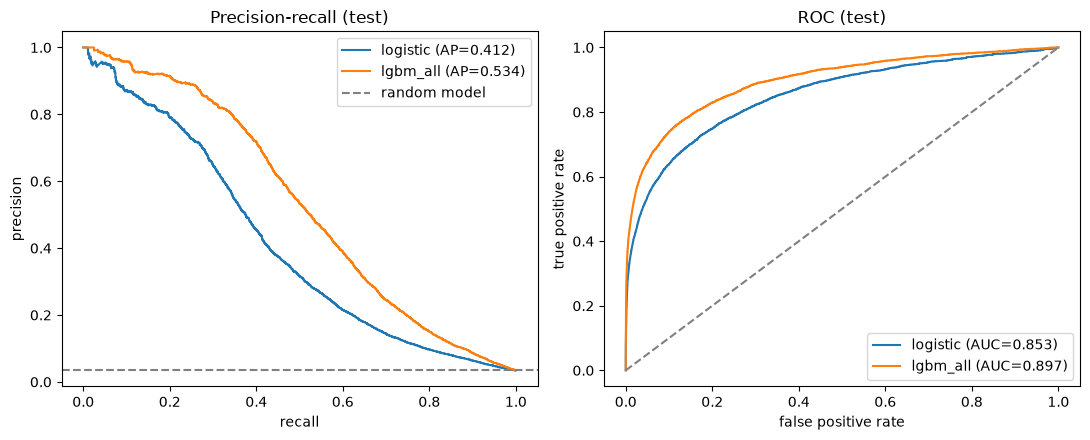

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name in ["logistic", "lgbm_all"]:
    p, r, _ = precision_recall_curve(y_test, scores[name]["test"])
    fpr, tpr, _ = roc_curve(y_test, scores[name]["test"])
    axes[0].plot(r, p, label=f"{name} (AP={results.loc[name, 'test_pr_auc']:.3f})")
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'test_roc_auc']:.3f})")
axes[0].axhline(y_test.mean(), color="gray", ls="--", label="random model")
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-recall (test)")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--")
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC (test)")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_pr_vs_roc.png", dpi=120, bbox_inches="tight")

## 4. Is each step a real improvement? Paired bootstrap on the test weeks

Both models are scored on the same resampled card holders, so the noise they share cancels. A CI that excludes 0 means the difference is unlikely to be luck.

In [10]:
comparisons = [("logistic", "lgbm_raw"), ("lgbm_raw", "lgbm_all"), ("lgbm_all", "lgbm_screened")]
diffs = pd.DataFrame([
    {"comparison": f"{b} - {a}", **paired_bootstrap_diff(y_test, scores[a]["test"], scores[b]["test"],
                                                         groups=test_entities, n_boot=N_BOOT, seed=SEED)._asdict()}
    for a, b in comparisons
]).set_index("comparison")
diffs.round(4)

,estimate,low,high
comparison,,,
lgbm_raw - logistic,0.0925,0.0685,0.1151
lgbm_all - lgbm_raw,0.0293,0.0145,0.0443
lgbm_screened - lgbm_all,-0.0267,-0.0410,-0.0132


## 5. What you resample changes the CI

Same model, same test set, three bootstraps:
- **rows**: assumes every transaction is independent;
- **days**: keeps a day's transactions together (fraud comes in bursts); 42 days in the test weeks;
- **card holders**: keeps each `entity_key` together (labels are linked per card holder).

In [11]:
final_name = "lgbm_screened" if diffs.loc["lgbm_screened - lgbm_all", "high"] > 0 else "lgbm_all"
print("final model:", final_name, "(the screened model is preferred unless it is clearly worse)")

s = scores[final_name]["test"]
widths = pd.DataFrame({
    name: bootstrap_ci(y_test, s, groups=g, n_boot=N_BOOT, seed=SEED)._asdict()
    for name, g in [("rows", None), ("days", test["day"]), ("card holders", test_entities)]
}).T
widths["width"] = widths["high"] - widths["low"]
widths["width_vs_rows"] = widths["width"] / widths.loc["rows", "width"]
widths.round(4)

final model: lgbm_all (the screened model is preferred unless it is clearly worse)


,estimate,low,high,width,width_vs_rows
rows,0.5337,0.5185,0.5490,0.0305,1.0000
days,0.5337,0.5036,0.5637,0.0601,1.9707
card holders,0.5337,0.5037,0.5614,0.0577,1.8911


## 6. Save scores and the final model for M3

In [12]:
final_model, final_features = models[final_name]
keep_cols = ["TransactionID", "week", "day", ENTITY_COL, "TransactionAmt", "ProductCD", TARGET]
out = pd.concat([
    valid[keep_cols].assign(split="valid", score=scores[final_name]["valid"]),
    test[keep_cols].assign(split="test", score=scores[final_name]["test"]),
], ignore_index=True)
out.to_parquet(PROCESSED_DIR / "scores_m2.parquet", index=False)
final_model.booster_.save_model(PROCESSED_DIR / "model_m2.txt")
(PROCESSED_DIR / "features_m2.json").write_text(json.dumps(final_features))
print(f"saved {len(out):,} scored rows, model {final_name} with {len(final_features)} features")

# Free memory: the next section refits the M1 models on two more copies of the data.
del models, grid, scores, train, valid, test, sample, out, final_model
gc.collect();

saved 204,242 scored rows, model lgbm_all with 447 features


## 7. M1 revisited, now with CIs

The M1 protocol exactly (fixed LightGBM, raw features, 80/20 split by time quantile), plus PR-AUC on test rows whose card holder **was** seen in training. Comparing seen vs unseen with the same model separates the two effects that the M1 drop mixed together.

In [13]:
def row(model, data):
    y, s = data[TARGET].to_numpy(), predict(model, data, raw_features)
    ci = bootstrap_ci(y, s, groups=data[ENTITY_COL], n_boot=N_BOOT, seed=SEED)
    return {"n_test": len(data), "fraud_rate": y.mean(), "pr_auc": ci.estimate, "ci_low": ci.low, "ci_high": ci.high}

# One split at a time, so only one extra copy of the data is in memory.
rand_train, rand_test = random_split(df, test_size=0.2, seed=0)
random_model = fit_baseline(rand_train, raw_features)
m1_rows = {"random": row(random_model, rand_test)}
del rand_train, rand_test, random_model
gc.collect()

m1_train, m1_test = time_split(df, test_size=0.2)
seen = m1_test[ENTITY_COL].isin(m1_train[ENTITY_COL].unique())
time_model = fit_baseline(m1_train, raw_features)
m1_rows |= {
    "time": row(time_model, m1_test),
    "time, seen card holders": row(time_model, m1_test[seen]),
    "time, unseen card holders": row(time_model, m1_test[~seen]),
}
m1 = pd.DataFrame(m1_rows).T
m1["lift"] = m1["pr_auc"] / m1["fraud_rate"]
m1.round(4)

,n_test,fraud_rate,pr_auc,ci_low,ci_high,lift
random,118174.0,0.0351,0.7659,0.7510,0.7801,21.7986
time,118108.0,0.0344,0.5672,0.5365,0.5989,16.4839
"time, seen card holders",51380.0,0.0199,0.6273,0.5383,0.7006,31.4435
"time, unseen card holders",66728.0,0.0455,0.5603,0.5284,0.5923,12.3026


## Takeaways

- **LightGBM beats logistic regression:** +0.093 PR-AUC [0.069, 0.115] (paired, card-holder bootstrap). Past-only behaviour features add +0.029 [0.015, 0.044].
- **Feature screening by mutual information hurts:** −0.027 [−0.041, −0.013]. Marginal statistics miss the interactions and missingness patterns that trees use, so the full feature set is kept.
- **The bootstrap unit matters.** Resampling card holders or days gives CIs about 1.9–2.0× wider than resampling rows (0.058 / 0.060 vs 0.031). Row-level CIs would overstate certainty.
- **M1 with CIs.** Random vs time split: [0.751, 0.780] vs [0.537, 0.599], clearly apart. Seen vs new card holders: 0.627 [0.538, 0.701] vs 0.560 [0.528, 0.592]. The CIs overlap, although the lift differs (31.4 vs 12.3), so memorisation is suggested but not proven.
- **The best ranking model has the worst log loss (0.171),** so its scores must be calibrated before any cost-based decision (notebook 04).